# Experiment 04: Batch size

Card: [exp04_batch_size.md](../../experiments/exp04_batch_size.md)


In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS
from ashrae.plots import GRID, INK, SURFACE, TEXT, style_axis
from src.data import fold_loaders
from src.networks import MeterMLP
from src.runs import finished_keys, fold_table, scores_at_best, session_scores
from src.tracking import Experiment
from src.training import fit_folds

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp04_batch_size"
EMB_DIM = 12  # picked in exp03
LR = 1e-3
THRESHOLD = 0.01
if SMOKE:
    EXPERIMENT = "ashrae-mlp-batch-size-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    BATCH_SIZES = [1024, 4096]
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-batch-size"
    TRAIN = True
    SESSION = None  # set to a finished session to reuse its runs; with TRAIN, only missing runs are trained
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    BATCH_SIZES = [1024, 2048, 4096, 8192, 16384]
    FIGURE = "../../figures/exp04_batch_size.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/12 15:01:13 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-mlp-batch-size' does not exist. Creating a new experiment.


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-batch-size', session 2026-10-12 15:01:13


## Training


In [2]:
def at_best(run_id):
    """`scores_at_best`, plus the training minutes up to the best epoch."""
    s = scores_at_best(experiment, run_id)
    seconds = experiment.history(run_id, "epoch_seconds")
    return {**s, "minutes_to_best": sum(seconds[: s["best_epoch"]]) / 60}


def scores():
    return session_scores(experiment, {"batch_size": int}, FOLD_NAMES, at_best=at_best)

In [3]:
if TRAIN:
    folds, n_buildings, n_features = fold_loaders(FOLD_NAMES, N_TRAIN, N_VAL)
    done = set() if SESSION is None else finished_keys(scores(), ["batch_size", "fold"])

    for batch_size in BATCH_SIZES:
        fit_folds(
            experiment,
            folds,
            lambda: MeterMLP(n_features, n_buildings, emb_dim=EMB_DIM),
            f"mlp_4out_emb | batch {batch_size}",
            done=done,
            key=(batch_size,),
            batch_size=batch_size,  # same scaled rows for every size, only the batching changes
            epochs=EPOCHS,
            lr=LR,
            tags={"model": "mlp_4out_emb", "batch_size": str(batch_size)},
            params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM},
        )

mlp_4out_emb | batch 1024 | Jan–Mar: 100%|██████████| 78160/78160 [03:48<00:00, 341.87batch/s, epoch 40, val 1.4122, best 1.4052 at 32]
mlp_4out_emb | batch 1024 | Apr–Jun: 100%|██████████| 78160/78160 [03:53<00:00, 335.36batch/s, epoch 40, val 1.2163, best 1.2097 at 25]
mlp_4out_emb | batch 1024 | Jul–Sep: 100%|██████████| 78160/78160 [03:51<00:00, 337.15batch/s, epoch 40, val 1.0218, best 1.0188 at 30]
mlp_4out_emb | batch 1024 | Oct–Dec: 100%|██████████| 78160/78160 [03:53<00:00, 335.28batch/s, epoch 40, val 1.1001, best 1.0994 at 29]
mlp_4out_emb | batch 2048 | Jan–Mar: 100%|██████████| 39080/39080 [02:19<00:00, 280.32batch/s, epoch 40, val 1.4093, best 1.4025 at 28]
mlp_4out_emb | batch 2048 | Apr–Jun: 100%|██████████| 39080/39080 [02:19<00:00, 279.90batch/s, epoch 40, val 1.2196, best 1.2116 at 33]
mlp_4out_emb | batch 2048 | Jul–Sep: 100%|██████████| 39080/39080 [02:09<00:00, 302.27batch/s, epoch 40, val 1.0236, best 1.0192 at 31]
mlp_4out_emb | batch 2048 | Oct–Dec: 100%|██████

## Results


In [4]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
table, by_size = fold_table(results, "batch_size", columns, FOLD_NAMES)
display(table.round(3))

within = by_size[by_size.val <= by_size.val.min() + THRESHOLD]
print(
    f"best: batch {by_size.val.idxmin()}; within {THRESHOLD} of it: {list(within.index)}; "
    f"fastest of those: batch {within.minutes_to_best.idxmin()}"
)

MLflow session 2026-10-12 15:01:13: 20 runs


"RMSLE at the best epoch, all rows unless noted",Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",best epoch,training,seconds per epoch,minutes to best epoch
batch_size,,,,,,,,,,
1024,1.405,1.210,1.019,1.099,1.183,0.922,29.00,0.791,5.606,2.729
2048,1.402,1.212,1.019,1.103,1.184,0.921,32.25,0.794,3.080,1.655
4096,1.408,1.210,1.025,1.100,1.186,0.923,35.25,0.797,1.717,1.009
8192,1.409,1.216,1.028,1.103,1.189,0.926,35.75,0.803,1.072,0.639
16384,1.410,1.218,1.039,1.103,1.192,0.931,38.25,0.814,0.729,0.465


best: batch 1024; within 0.01 of it: [1024, 2048, 4096, 8192, 16384]; fastest of those: batch 16384


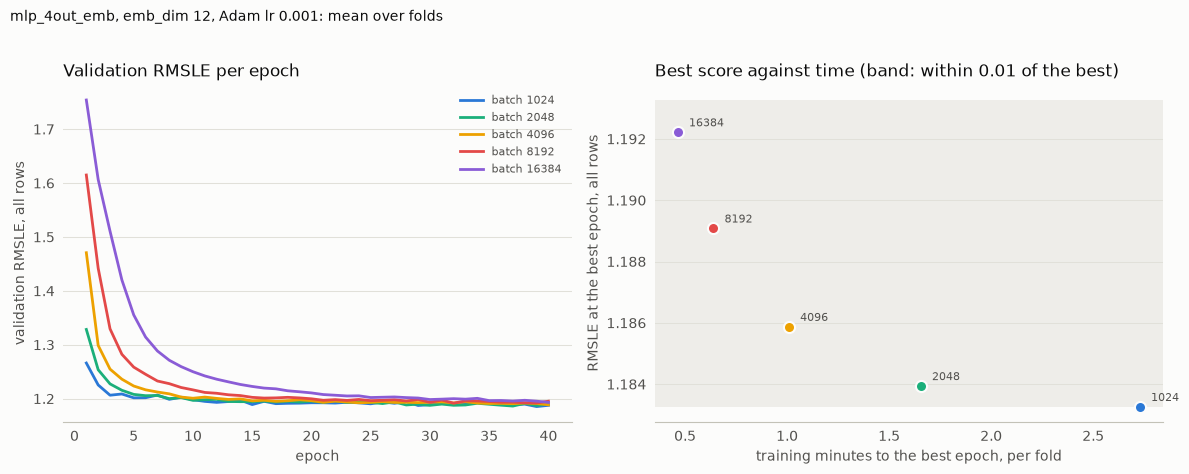

In [ ]:
COLORS = dict(zip(BATCH_SIZES, ["#2a78d6", "#1baf7a", "#eda100", "#e34948", "#8a5cd6"]))
epochs = np.arange(1, EPOCHS + 1)

fig, (ax_ep, ax_t) = plt.subplots(1, 2, figsize=(12, 4.6), facecolor=SURFACE)
for batch_size, color in COLORS.items():
    runs = results[results.batch_size == batch_size]
    ax_ep.plot(
        epochs,
        np.mean(runs.val_curve.tolist(), axis=0),
        color=color,
        lw=2,
        label=f"batch {batch_size}",
    )
    row = by_size.loc[batch_size]
    ax_t.plot(
        row.minutes_to_best,
        row.val,
        color=color,
        marker="o",
        ms=8,
        mec=SURFACE,
        mew=1.5,
    )
    ax_t.annotate(
        f"{batch_size}",
        (row.minutes_to_best, row.val),
        xytext=(8, 4),
        textcoords="offset points",
        color=TEXT,
        fontsize=8,
    )
ax_t.axhspan(
    by_size.val.min(), by_size.val.min() + THRESHOLD, color=GRID, alpha=0.5, lw=0
)
ax_ep.set(xlabel="epoch", ylabel="validation RMSLE, all rows")
ax_ep.set_title("Validation RMSLE per epoch", loc="left", color=INK)
ax_t.set(
    xlabel="training minutes to the best epoch, per fold",
    ylabel="RMSLE at the best epoch, all rows",
)
ax_t.set_title(
    f"Best score against time (band: within {THRESHOLD} of the best)",
    loc="left",
    color=INK,
)
for ax in (ax_ep, ax_t):
    style_axis(ax)
ax_ep.legend(frameon=False, fontsize=8, labelcolor=TEXT)
fig.suptitle(
    f"mlp_4out_emb, emb_dim {EMB_DIM}, Adam lr {LR:g}: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
    y=1.02,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.run_id:
        experiment.client.log_artifact(run_id, FIGURE)